In [ ]:

#기본환경설정
# 1. 구글 드라이브 마운트 (Google Drive Mount)
from google.colab import drive
drive.mount('/content/drive')

# 2. 작업 디렉토리(Directory) 이동 (본인의 실제 프로젝트 경로로 수정)
import os, subprocess, time, urllib.request
os.chdir('/content/drive/MyDrive/knot_dataset')

# 3. requirements.txt를 통한 기본 라이브러리 일괄 설치
!pip install -r requirements.txt

# 4. PyTorch 버전 및 CUDA 버전에 맞춘 PyTorch Geometric 전용 설치
# (참고: 아래 URL의 'torch-2.0.0+cu118' 부분은 현재 코랩 버전 상태에 따라 에러 발생 시 수정이 필요할 수 있습니다)
!pip install torch_geometric
!pip install pyg_lib torch_scatter torch_sparse torch_cluster torch_spline_conv -f https://data.pyg.org/whl/torch-2.0.0+cu118.html
!pip install -q ultralytics opencv-python scikit-image pyknotid networkx label-studio label-studio-sdk

print("모든 환경 설정 및 라이브러리 설치가 완료되었습니다.")


In [ ]:
#이미지 파일 형태 조회 코드

from pathlib import Path
from PIL import Image
from collections import Counter

# 경로 (Colab에서는 이렇게 씁니다)
ROOT = Path("/content/drive/MyDrive/knot_dataset/10knots/knot_labeling_image_data/knot_image_data/Figure-8 Loop")

sizes, mb = [], []
for p in ROOT.rglob("*"):
    if p.suffix.lower() in (".jpg", ".jpeg", ".png"):
        try:
            with Image.open(p) as im:
                sizes.append(im.size)
            mb.append(p.stat().st_size / 1024 / 1024)
        except Exception:
            pass

print(f"사진: {len(sizes)}장")
print(f"평균 용량: {sum(mb)/len(mb):.2f} MB")
print(f"가장 큰 것: {max(mb):.2f} MB")
print("\n[많이 나오는 크기]")
for s, n in Counter(sizes).most_common(8):
    print(f"  {s[0]} x {s[1]} : {n}장")

In [ ]:
import roboflow

# 1. 강제 재로그인 (Force Login) 실행을 통해 인증 충돌 해결
roboflow.login(force=True)

# 2. 로보플로우 객체 (Object) 생성 및 프로젝트 연결
rf = roboflow.Roboflow()

roboflow.login()

# 주의: 주소창(URL)에서 확인한 정확한 Workspace ID와 Project ID를 따옴표 안에 입력해야 합니다.
project = rf.workspace("s-workspace-auvcz").project("10knots")

# 3. 절대 경로 (Absolute Path) 설정
TARGET_PATH = "knot_dataset/10knots/Knot_origianal_data"

# 4. 이미지 업로드 (Upload) 실행
project.upload(TARGET_PATH)

In [ ]:
import os
import time
import roboflow

# 1. 로그인 및 프로젝트 연결
roboflow.login()
rf = roboflow.Roboflow()
project = rf.workspace("s-workspace-auvcz").project("10knots")

# 2. 절대 경로 (Absolute Path) 및 설정
TARGET_PATH = "/content/drive/MyDrive/knot_dataset/10knots/Knot_origianal_data"
valid_extensions = [".jpg", ".jpeg", ".png"]

# 3. 재시도 로직이 포함된 업로드 함수 (Upload Function)
def upload_file_with_retry(project_obj, file_path, max_retries=3, delay=2):
    for attempt in range(max_retries):
        try:
            project_obj.upload(file_path)
            return True
        except Exception as e:
            print(f"\n[경고] {os.path.basename(file_path)} 업로드 실패 (에러: {e}). {delay}초 후 재시도합니다... ({attempt + 1}/{max_retries})")
            time.sleep(delay)
    return False

# 4. 순회 및 업로드 진행
success_count = 0
failed_files = []

for root, dirs, files in os.walk(TARGET_PATH):
    for file in files:
        ext = os.path.splitext(file)[1].lower()
        if ext in valid_extensions:
            file_path = os.path.join(root, file)
            print(f"업로드 진행 중: {file_path}")
            
            # API 과부하 방지를 위한 0.3초 시간 지연 (Time Delay)
            time.sleep(0.3)
            
            # 업로드 실행
            if upload_file_with_retry(project, file_path):
                success_count += 1
            else:
                failed_files.append(file_path)

# 5. 최종 결과 출력
print("\n" + "="*50)
print(f"업로드 완료! 성공: {success_count}건, 실패: {len(failed_files)}건")
if failed_files:
    print("실패한 파일 목록:")
    for f in failed_files:
        print(f)
print("="*50)

In [12]:
import os
import cv2
import numpy as np


# 3. 경로 설정
SOURCE_PATH = r"G:\내 드라이브\knot_dataset\10knots\Knot_sm_data"
OUTPUT_PATH = r"G:\내 드라이브\knot_dataset\10knots\Knot_re_data"

# 지원할 이미지 확장자 (대소문자 자동 처리)
valid_extensions = [".jpg", ".jpeg", ".png", ".webp"]

# 경로 존재 여부 점검
if not os.path.exists(SOURCE_PATH):
    print(f"\n❌ [경고] 지정하신 경로가 존재하지 않습니다: {SOURCE_PATH}")
    print("👉 구글 드라이브 내 실제 폴더 이름을 다시 한번 확인해 주세요!")
else:
    print(f"\n✅ 경로 확인 성공: {SOURCE_PATH}")

def apply_letterbox(image_path, target_size=(640, 640), bg_color=(0, 0, 0)):
    """비율을 보존하며 중앙에 배치하고 여백을 검은색으로 채웁니다."""
    try:
        img_array = np.fromfile(image_path, np.uint8)
        img = cv2.imdecode(img_array, cv2.IMREAD_COLOR)
        
        if img is None:
            return None

        h, w, _ = img.shape
        target_w, target_h = target_size

        scale = min(target_w / w, target_h / h)
        new_w = int(w * scale)
        new_h = int(h * scale)

        resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
        canvas = np.full((target_h, target_w, 3), bg_color, dtype=np.uint8)

        top = (target_h - new_h) // 2
        left = (target_w - new_w) // 2
        canvas[top:top+new_h, left:left+new_w] = resized

        return canvas
    except Exception as e:
        return None

print("\n🚀 이미지 변환 작업을 시작합니다...\n")
converted_count = 0

for root, dirs, files in os.walk(SOURCE_PATH):
    for file in files:
        # 확장자를 소문자로 변환해 대소문자 차이 방지
        ext = os.path.splitext(file)[1].lower()
        if ext in valid_extensions:
            src_file_path = os.path.join(root, file)
            
            # 원본 하위 폴더 트리를 그대로 계산하여 동일 생성
            rel_path = os.path.relpath(root, SOURCE_PATH)
            save_dir = os.path.join(OUTPUT_PATH, rel_path)
            os.makedirs(save_dir, exist_ok=True)
            
            save_file_path = os.path.join(save_dir, file)
            
            # 레터박스 변환
            processed_img = apply_letterbox(src_file_path, target_size=(640, 640))
            
            if processed_img is not None:
                result, encoded_img = cv2.imencode(ext, processed_img)
                if result:
                    encoded_img.tofile(save_file_path)
                    converted_count += 1

            if converted_count % 50 == 0 and converted_count > 0:
                print(f"📸 현재까지 {converted_count}장 변환 완료... (위치: {rel_path})")

print("\n" + "="*60)
print(f"🎉 작업 완료! 총 {converted_count}장의 사진이 정상 변환되었습니다.")
print(f"📁 저장 장소: {OUTPUT_PATH}")
print("="*60)


✅ 경로 확인 성공: G:\내 드라이브\knot_dataset\10knots\Knot_sm_data

🚀 이미지 변환 작업을 시작합니다...

📸 현재까지 50장 변환 완료... (위치: Clove Hitch)
📸 현재까지 100장 변환 완료... (위치: Bowline Knot)
📸 현재까지 150장 변환 완료... (위치: Overhand Knot)
📸 현재까지 200장 변환 완료... (위치: Fisherman's Knot)

🎉 작업 완료! 총 205장의 사진이 정상 변환되었습니다.
📁 저장 장소: G:\내 드라이브\knot_dataset\10knots\Knot_re_data


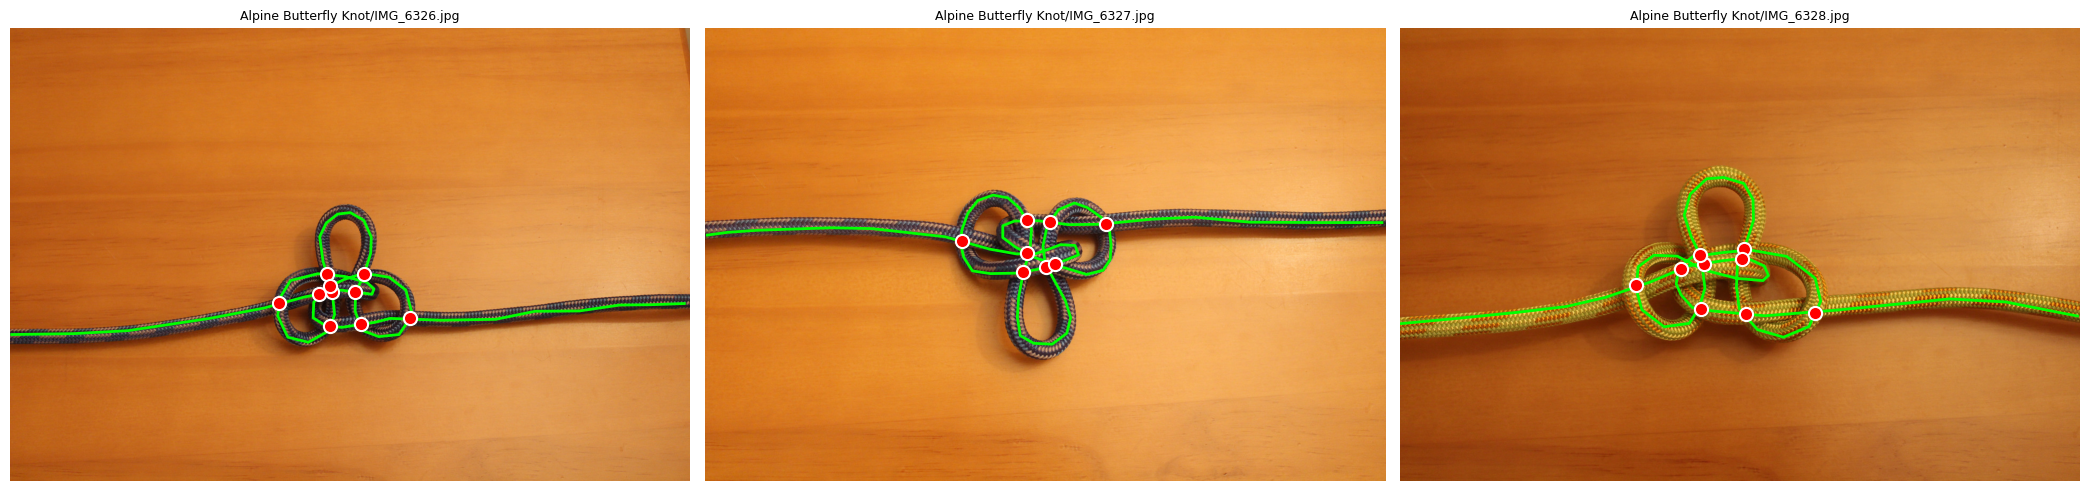

In [ ]:
#이미지 축소 코드 
# -*- coding: utf-8 -*-
"""
이미지 크기 줄이기  ── 폴더 계층 유지 버전

하는 일:
  1. 하위 폴더를 전부 훑어서 사진을 찾음
  2. 긴 변 기준으로 크기를 줄임 (기본 1280)
  3. 라벨 JSON 의 점 좌표도 같은 비율로 줄임
  4. 원본과 똑같은 폴더 구조로 저장
  5. EXIF 회전 정보를 픽셀에 반영

설치할 것 없음 (PIL 은 Colab 에 기본 설치됨)

사용법:
  아래 [설정] 만 고치고 실행.
  처음엔 DRY_RUN = True 로 미리보기.
"""

import json
from collections import Counter
from pathlib import Path

from PIL import Image, ImageOps

Image.MAX_IMAGE_PIXELS = None

# ============================================================
# [설정] 이 부분만 고치세요
# ============================================================

# 원본 (사진)
SRC_IMG = "/content/drive/MyDrive/knot_dataset/10knots/knot_labeling_image_data/original_label_data/knot_image_data"

# 원본 (라벨 JSON)
#   사진과 같은 폴더에 섞여 있으면 SRC_IMG 와 똑같이 두세요.
SRC_JSON = "/content/drive/MyDrive/knot_dataset/10knots/knot_labeling_image_data/original_label_data/knot_label_data"

# 결과
OUT_IMG  = "/content/drive/MyDrive/knot_dataset/10knots/knot_labeling_image_data/preprocessing_data/pre_knot_image_data"
OUT_JSON = "/content/drive/MyDrive/knot_dataset/10knots/knot_labeling_image_data/preprocessing_data/pre_knot_label_data"

MAX_SIDE = 1280      # 긴 변을 이 크기로. 0 이면 크기 안 줄이고 정리만.
QUALITY  = 92        # JPEG 품질 (90~95 권장)

DRY_RUN  = False      # True 면 실제로 저장 안 하고 미리보기만

# 라벨 JSON 을 어떻게 찾을지
#   "same"  : 사진과 같은 하위 폴더 안에서 찾기 (기본)
#   "flat"  : SRC_JSON 바로 아래에 다 모여 있음
#   "any"   : 어디 있든 이름으로 전체 검색
JSON_MODE = "same"

# ============================================================


def find_json(stem: str, rel_parent: Path, src_json: Path):
    """라벨 파일 찾기 — 여러 방식을 순서대로 시도"""
    if JSON_MODE in ("same", "any"):
        c = src_json / rel_parent / f"{stem}.json"
        if c.exists():
            return c
    if JSON_MODE in ("flat", "any", "same"):
        c = src_json / f"{stem}.json"
        if c.exists():
            return c
    if JSON_MODE == "any":
        hits = list(src_json.rglob(f"{stem}.json"))
        if hits:
            return hits[0]
    return None


def main():
    src_img  = Path(SRC_IMG)
    src_json = Path(SRC_JSON)
    out_img  = Path(OUT_IMG)
    out_json = Path(OUT_JSON)

    if not src_img.exists():
        print(f"[중단] 폴더가 없습니다: {src_img}")
        print("       Drive 마운트를 했는지, 경로가 맞는지 확인하세요.")
        return

    exts = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff")
    images = sorted(p for p in src_img.rglob("*")
                    if p.is_file()
                    and p.suffix.lower() in exts
                    and not p.name.startswith("."))

    if not images:
        print(f"[중단] 사진을 찾지 못했습니다: {src_img}")
        return

    print(f"사진 {len(images)}장 발견\n")

    # --- 폴더별 개수 미리 보기 ---
    folders = Counter(str(p.parent.relative_to(src_img)) for p in images)
    print("[폴더별 사진 수]")
    for k, v in sorted(folders.items()):
        print(f"  {k if k != '.' else '(최상위)'} : {v}장")
    print()

    done, nolabel, failed = 0, [], []
    size_before, size_after = 0, 0
    sample = None

    for p in images:
        rel_parent = p.parent.relative_to(src_img)

        try:
            with Image.open(p) as im:
                im = ImageOps.exif_transpose(im)          # 회전 정보를 픽셀에 반영
                if im.mode != "RGB":
                    im = im.convert("RGB")

                w, h = im.size
                if MAX_SIDE and max(w, h) > MAX_SIDE:
                    r = MAX_SIDE / max(w, h)
                    nw, nh = round(w * r), round(h * r)
                    im = im.resize((nw, nh), Image.LANCZOS)
                else:
                    r, nw, nh = 1.0, w, h

                dst_i = out_img / rel_parent / f"{p.stem}.jpg"
                if not DRY_RUN:
                    dst_i.parent.mkdir(parents=True, exist_ok=True)
                    im.save(dst_i, "JPEG", quality=QUALITY,
                            subsampling=0, optimize=True)
                    size_after += dst_i.stat().st_size

            size_before += p.stat().st_size
            if sample is None:
                sample = (p.name, (w, h), (nw, nh), r)

        except Exception as e:
            failed.append((p.name, f"{e.__class__.__name__}: {e}"))
            continue

        # --- 라벨 좌표도 같은 비율로 ---
        jp = find_json(p.stem, rel_parent, src_json)
        if jp is None:
            nolabel.append(str(rel_parent / p.name))
        else:
            try:
                d = json.loads(jp.read_text(encoding="utf-8"))
                for s in d.get("shapes", []):
                    s["points"] = [[float(x) * r, float(y) * r]
                                   for x, y in s.get("points", [])]
                d["imagePath"] = f"{p.stem}.jpg"
                d["imageWidth"], d["imageHeight"] = nw, nh
                d.pop("imageData", None)          # 용량 큰 base64 제거

                dst_j = out_json / rel_parent / f"{p.stem}.json"
                if not DRY_RUN:
                    dst_j.parent.mkdir(parents=True, exist_ok=True)
                    dst_j.write_text(
                        json.dumps(d, ensure_ascii=False, indent=2),
                        encoding="utf-8")
            except Exception as e:
                failed.append((jp.name, f"라벨처리실패: {e}"))

        done += 1
        if done % 100 == 0:
            print(f"  ... {done}/{len(images)}")

    # --- 결과 ---
    print("\n" + "=" * 50)
    print("DRY RUN (실제로 저장 안 됨)" if DRY_RUN else "완료")
    print("=" * 50)
    print(f"처리한 사진 : {done}장")

    if sample:
        n, (w, h), (nw, nh), r = sample
        print(f"크기 변화   : {w}x{h}  ->  {nw}x{nh}   (배율 {r:.3f})")

    if not DRY_RUN and size_before:
        print(f"용량        : {size_before/1024/1024:.0f} MB "
              f"-> {size_after/1024/1024:.0f} MB")

    if nolabel:
        print(f"\n라벨 없는 사진 : {len(nolabel)}장")
        for x in nolabel[:10]:
            print(f"    {x}")
        if len(nolabel) > 10:
            print(f"    ... 외 {len(nolabel)-10}장")
        print("  -> 라벨이 다른 폴더에 있으면 JSON_MODE 를 'any' 로 바꿔보세요.")

    if failed:
        print(f"\n실패 : {len(failed)}건")
        for n, e in failed[:10]:
            print(f"    {n} : {e}")

    if not DRY_RUN:
        print("\n[결과 폴더 구조]")
        for d in sorted(out_img.rglob("*")):
            if d.is_dir():
                n = len([x for x in d.iterdir() if x.is_file()])
                print(f"  {d.relative_to(out_img)}/ : {n}장")

    if DRY_RUN:
        print("\n결과가 괜찮으면 DRY_RUN = False 로 바꾸고 다시 실행하세요.")


# ============================================================
# 확인용: 점이 제대로 줄었는지 눈으로 보기
# ============================================================
def check(n=3):
    import matplotlib.pyplot as plt
    import numpy as np
    import cv2

    out_img, out_json = Path(OUT_IMG), Path(OUT_JSON)
    files = sorted(out_img.rglob("*.jpg"))[:n]
    if not files:
        print("결과가 없습니다. DRY_RUN = False 로 main() 을 먼저 실행하세요.")
        return

    fig, axes = plt.subplots(1, len(files), figsize=(7 * len(files), 7))
    if len(files) == 1:
        axes = [axes]

    for ax, p in zip(axes, files):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        ax.imshow(img)

        rel = p.parent.relative_to(out_img)
        jp = out_json / rel / f"{p.stem}.json"
        if jp.exists():
            d = json.loads(jp.read_text(encoding="utf-8"))
            for s in d.get("shapes", []):
                a = np.array(s["points"])
                if a.size == 0:
                    continue
                if "crossing" in s.get("label", "").lower():
                    ax.scatter(a[:, 0], a[:, 1], c="red", s=90,
                               edgecolors="white", linewidths=1.5, zorder=3)
                elif "anchor" in s.get("label", "").lower():
                    ax.plot(*np.append(a, a[:1], axis=0).T, c="yellow", lw=2)
                else:
                    ax.plot(a[:, 0], a[:, 1], c="lime", lw=2)
        else:
            ax.set_xlabel("라벨 없음")

        ax.set_title(f"{rel}/{p.name}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()
    # 저장까지 끝냈으면 아래 주석을 풀고 확인하세요
    check(3)

In [7]:
!pip install -q transformers
!pip install -q icrawler imagehash

In [13]:
!mkdir -p /content/data2/Bowline Knot
!mkdir -p /content/data2/Clove Hitch
!mkdir -p /content/data2/Figure-8 Knot
!mkdir -p /content/data2/Figure-8 Loop
!mkdir -p /content/data2/Fishermans Knot
!mkdir -p /content/data2/Overhand Knot
!mkdir -p /content/data2/Reef Knot
!mkdir -p /content/data2/Slip Knot

!ls /content/data2


Alpine	Bowline  Clove	Figure-8  Fishermans  Overhand	Reef  Slip


In [17]:
%%writefile /content/knot_image_crawler.py
#!/usr/bin/env python
# -*- coding: utf-8 -*-
"""
knot_image_crawler.py
---------------------
지정한 루트 아래의 "말단 폴더(leaf folder)" 이름을 검색어로 사용해
웹에서 매듭 이미지를 수집하고, 해당 폴더에 그대로 저장한다.

예시)
    dataset/
      knots/
        bowline/          -> 검색어 "bowline knot"  -> dataset/knots/bowline/ 에 저장
        figure_eight/     -> 검색어 "figure eight knot"
        clove_hitch/      -> 검색어 "clove hitch knot"

설치:
    pip install icrawler pillow imagehash opencv-python-headless
    # CLIP 필터를 쓸 경우 추가
    pip install torch transformers

사용:
    python knot_image_crawler.py --root ./dataset/knots --num 300
    python knot_image_crawler.py --root ./dataset/knots --num 300 --clip
    python knot_image_crawler.py --root ./dataset/knots --dry-run
"""

import argparse
import logging
import re
import shutil
import sys
import tempfile
from pathlib import Path

import imagehash
from PIL import Image, ImageStat, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = False  # 잘린 이미지는 에러로 잡아서 버린다

# --------------------------------------------------------------------------
# 1. 설정
# --------------------------------------------------------------------------

VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# 폴더명 -> 검색어 보정 (언더바/하이픈은 자동으로 공백 처리됨)
# 필요한 매듭만 여기에 추가하면 된다. 없으면 폴더명 + SUFFIX 로 검색.
QUERY_MAP = {
    "figure_eight": "figure eight knot rope",
    "figure_8": "figure eight follow through knot",
    "bowline": "bowline knot rope",
    "clove_hitch": "clove hitch knot rope",
    "double_fisherman": "double fisherman's knot rope",
    "alpine_butterfly": "alpine butterfly knot rope",
    "prusik": "prusik hitch knot rope",
    "munter_hitch": "munter hitch carabiner",
    "girth_hitch": "girth hitch sling",
    "overhand": "overhand knot rope",
    "Fishermans": "Fisherman's Knot",
}

# 폴더명에 이미 이런 단어가 있으면 "knot"을 덧붙이지 않는다
KNOT_TERMS = {"Knot", "hitch", "bend", "Loop", "noose",
              "splice", "lashing", "whipping", "coil"}

# 매핑에 없는 폴더에 붙일 기본 접미사 토큰 (중복은 자동으로 걸러짐)
DEFAULT_SUFFIX_TOKENS = ["knot", "rope"]

# 여러 변형 쿼리로 나눠서 수집하면 중복이 줄고 다양성이 올라간다
QUERY_VARIANTS = [
    "{q}",
    "{q} close up",
    "{q} tied",
    "{q} climbing",
]

# --------------------------------------------------------------------------
# 2. 필터 임계값
# --------------------------------------------------------------------------

MIN_W, MIN_H = 200, 200          # 최소 해상도
MAX_ASPECT = 3.0                 # 가로/세로 비율 상한 (배너·띠 이미지 제거)
MIN_FILESIZE = 8 * 1024          # 8KB 미만은 썸네일/깨진 파일
MIN_STDDEV = 12.0                # 픽셀 표준편차: 단색·백지·로고 제거
PHASH_DISTANCE = 5               # 이 해밍거리 이하면 중복으로 간주
BLUR_THRESHOLD = 40.0            # Laplacian variance, 낮으면 흐릿한 이미지


# --------------------------------------------------------------------------
# 3. 유틸
# --------------------------------------------------------------------------

def _normalize(name: str) -> str:
    """'Slip_Knot', 'slip knot', 'slip-knot' -> 'slip knot' 으로 통일."""
    s = re.sub(r"[_\-]+", " ", name.strip().lower())
    return re.sub(r"\s+", " ", s).strip()


def folder_to_query(folder_name: str) -> str:
    """폴더명을 검색어로 변환. 이미 들어있는 단어는 다시 붙이지 않는다."""
    key = _normalize(folder_name)

    # QUERY_MAP은 키를 정규화해서 조회 (언더바/공백 어느 쪽으로 써도 매칭)
    for map_key, mapped in QUERY_MAP.items():
        if _normalize(map_key) == key:
            return mapped

    tokens = key.split()
    present = set(tokens)
    out = list(tokens)

    for suffix in DEFAULT_SUFFIX_TOKENS:
        if suffix in present:
            continue
        # 'hitch', 'bend' 등이 이미 있으면 'knot'은 생략
        if suffix == "knot" and (present & KNOT_TERMS):
            continue
        out.append(suffix)
        present.add(suffix)

    return " ".join(out)


def safe_prefix(name: str) -> str:
    """폴더명을 파일명 접두사로 쓸 수 있게 정리."""
    return re.sub(r"[^0-9a-zA-Z]+", "_", name).strip("_").lower() or "img"


def find_leaf_folders(root: Path):
    """하위 디렉토리가 없는 폴더(=클래스 폴더)만 수집. 구조는 그대로 유지."""
    leaves = []
    for p in sorted(root.rglob("*")):
        if not p.is_dir():
            continue
        if p.name.startswith("."):
            continue
        if any(child.is_dir() for child in p.iterdir()):
            continue
        leaves.append(p)
    # 루트 자체가 말단인 경우
    if not leaves and root.is_dir():
        leaves = [root]
    return leaves


# --------------------------------------------------------------------------
# 4. 수집
# --------------------------------------------------------------------------

def crawl_to_staging(query: str, staging: Path, max_num: int, engines):
    """여러 엔진 / 여러 변형 쿼리로 staging 디렉토리에 원본을 모은다."""
    from icrawler.builtin import BingImageCrawler, GoogleImageCrawler, BaiduImageCrawler

    engine_map = {
        "bing": BingImageCrawler,
        "google": GoogleImageCrawler,
        "baidu": BaiduImageCrawler,
    }

    per_job = max(10, max_num // max(1, len(engines) * len(QUERY_VARIANTS)))

    for engine in engines:
        cls = engine_map.get(engine)
        if cls is None:
            print(f"    [!] 알 수 없는 엔진: {engine}")
            continue

        for vi, variant in enumerate(QUERY_VARIANTS):
            q = variant.format(q=query)
            out_dir = staging / f"{engine}_{vi}"
            out_dir.mkdir(parents=True, exist_ok=True)

            crawler = cls(
                feeder_threads=1,
                parser_threads=2,
                downloader_threads=6,
                storage={"root_dir": str(out_dir)},
                log_level=logging.ERROR,
            )

            kwargs = {
                "keyword": q,
                "max_num": per_job,
                "min_size": (MIN_W, MIN_H),
                "file_idx_offset": 0,
            }
            # 사진 위주로 받아서 일러스트/클립아트 노이즈를 애초에 줄인다
            if engine in ("bing", "google"):
                kwargs["filters"] = {"type": "photo", "size": "medium"}

            try:
                crawler.crawl(**kwargs)
            except Exception as e:
                print(f"    [!] {engine} '{q}' 실패: {e}")


# --------------------------------------------------------------------------
# 5. 노이즈 제거
# --------------------------------------------------------------------------

def basic_checks(path: Path):
    """열림/해상도/비율/단색 여부 검사. 통과 시 PIL Image 반환, 아니면 (None, 사유)."""
    if path.suffix.lower() not in VALID_EXT:
        return None, "ext"
    if path.stat().st_size < MIN_FILESIZE:
        return None, "filesize"

    try:
        with Image.open(path) as probe:
            probe.verify()          # 손상 여부 1차 검사
        img = Image.open(path)
        img = img.convert("RGB")     # 실제 디코딩 (여기서 truncated 걸러짐)
    except Exception:
        return None, "corrupt"

    w, h = img.size
    if w < MIN_W or h < MIN_H:
        return None, "small"
    if max(w / h, h / w) > MAX_ASPECT:
        return None, "aspect"

    stat = ImageStat.Stat(img)
    if sum(stat.stddev) / len(stat.stddev) < MIN_STDDEV:
        return None, "flat"          # 단색 배경, 백지, 단순 로고

    return img, None


def is_blurry(img: Image.Image) -> bool:
    """Laplacian variance 기반 흐림 판정. cv2 없으면 항상 False."""
    try:
        import cv2
        import numpy as np
    except ImportError:
        return False
    small = img.resize((256, 256))
    gray = cv2.cvtColor(np.array(small), cv2.COLOR_RGB2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var() < BLUR_THRESHOLD


class ClipFilter:
    """CLIP으로 '실제 매듭 사진'인지 판정. 도표/텍스트/인물/제품광고 등을 제거."""

    NEG_PROMPTS = [
        "a cartoon or line drawing diagram",
        "a screenshot of a web page with text",
        "a company logo or watermark",
        "a portrait photo of a person's face",
        "an advertisement product listing",
        "a landscape or scenery photo",
        "a chart, table, or infographic",
    ]

    def __init__(self, threshold=0.35, device=None):
        import torch
        from transformers import CLIPModel, CLIPProcessor

        self.torch = torch
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(self.device)
        self.model.eval()
        self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
        self.threshold = threshold
        self._cache = {}

    def build_prompts(self, query: str):
        pos = [
            f"a photograph of a {query}",
            f"a close-up photo of rope tied into a {query}",
            "a photograph of a knotted rope",
        ]
        return pos, self.NEG_PROMPTS

    def keep(self, img: Image.Image, query: str) -> bool:
        pos, neg = self._cache.setdefault(query, self.build_prompts(query))
        texts = pos + neg
        inputs = self.processor(text=texts, images=img, return_tensors="pt",
                                padding=True, truncation=True).to(self.device)
        with self.torch.no_grad():
            out = self.model(**inputs)
            probs = out.logits_per_image.softmax(dim=1)[0]
        pos_score = float(probs[:len(pos)].sum())
        return pos_score >= self.threshold


def clean_and_move(staging: Path, target: Path, query: str,
                   clip: "ClipFilter | None", blur_check: bool,
                   global_hashes: dict, max_keep: int):
    """staging의 이미지를 필터링 후 target에 순번 이름으로 저장."""
    stats = {"ext": 0, "filesize": 0, "corrupt": 0, "small": 0,
             "aspect": 0, "flat": 0, "blur": 0, "dup": 0, "clip": 0, "kept": 0}

    # 기존 파일들의 해시를 먼저 등록 (재실행 시 중복 방지)
    local_hashes = {}
    for existing in sorted(target.iterdir()):
        if existing.is_file() and existing.suffix.lower() in VALID_EXT:
            try:
                with Image.open(existing) as im:
                    local_hashes[imagehash.phash(im.convert("RGB"))] = existing
            except Exception:
                pass

    start_idx = len(local_hashes)
    idx = start_idx
    prefix = safe_prefix(target.name)

    candidates = [p for p in sorted(staging.rglob("*")) if p.is_file()]

    for src in candidates:
        if stats["kept"] >= max_keep:
            break

        img, reason = basic_checks(src)
        if img is None:
            stats[reason] = stats.get(reason, 0) + 1
            continue

        # 중복 제거 (폴더 내 + 전역)
        h = imagehash.phash(img)
        dup = False
        for pool in (local_hashes, global_hashes):
            for known in pool:
                if h - known <= PHASH_DISTANCE:
                    dup = True
                    break
            if dup:
                break
        if dup:
            stats["dup"] += 1
            img.close()
            continue

        if blur_check and is_blurry(img):
            stats["blur"] += 1
            img.close()
            continue

        if clip is not None and not clip.keep(img, query):
            stats["clip"] += 1
            img.close()
            continue

        idx += 1
        dst = target / f"{prefix}_{idx:04d}.jpg"
        try:
            img.save(dst, "JPEG", quality=92)
        except Exception:
            img.close()
            continue

        local_hashes[h] = dst
        global_hashes[h] = dst
        stats["kept"] += 1
        img.close()

    return stats


# --------------------------------------------------------------------------
# 6. 메인
# --------------------------------------------------------------------------

def main():
    ap = argparse.ArgumentParser(description="폴더명 기반 매듭 이미지 크롤러")
    ap.add_argument("--root", required=True, help="클래스 폴더들이 들어있는 루트 경로")
    ap.add_argument("--num", type=int, default=200, help="클래스당 목표 수집 장수")
    ap.add_argument("--engines", default="bing,google",
                    help="쉼표 구분: bing,google,baidu")
    ap.add_argument("--clip", action="store_true", help="CLIP 관련성 필터 사용")
    ap.add_argument("--clip-threshold", type=float, default=0.35)
    ap.add_argument("--blur", action="store_true", help="흐린 이미지 제거(cv2 필요)")
    ap.add_argument("--global-dedup", action="store_true",
                    help="클래스 간 중복까지 제거 (같은 이미지가 두 클래스에 들어가는 것 방지)")
    ap.add_argument("--dry-run", action="store_true",
                    help="다운로드 없이 폴더-검색어 매핑만 출력")
    args = ap.parse_args()

    root = Path(args.root).expanduser().resolve()
    if not root.is_dir():
        print(f"[X] 루트 폴더가 없습니다: {root}")
        sys.exit(1)

    leaves = find_leaf_folders(root)
    if not leaves:
        print("[X] 말단 폴더를 찾지 못했습니다.")
        sys.exit(1)

    print(f"\n루트: {root}")
    print(f"대상 폴더 {len(leaves)}개\n" + "-" * 60)
    for leaf in leaves:
        rel = leaf.relative_to(root)
        print(f"  {rel}  ->  \"{folder_to_query(leaf.name)}\"")
    print("-" * 60)

    if args.dry_run:
        print("\n[dry-run] 실제 다운로드는 하지 않았습니다.")
        return

    clip = None
    if args.clip:
        print("\nCLIP 모델 로딩 중...")
        clip = ClipFilter(threshold=args.clip_threshold)
        print(f"  device = {clip.device}")

    engines = [e.strip() for e in args.engines.split(",") if e.strip()]
    global_hashes = {} if args.global_dedup else {}
    use_global = args.global_dedup

    total_kept = 0
    for i, leaf in enumerate(leaves, 1):
        query = folder_to_query(leaf.name)
        print(f"\n[{i}/{len(leaves)}] {leaf.relative_to(root)}  <-  \"{query}\"")

        with tempfile.TemporaryDirectory(prefix="knot_dl_") as tmp:
            staging = Path(tmp)
            # 여유 있게 받아서 필터로 깎는다 (노이즈 제거 후 목표치를 맞추기 위함)
            crawl_to_staging(query, staging, int(args.num * 2.5), engines)

            raw_count = sum(1 for p in staging.rglob("*") if p.is_file())
            print(f"    수집 원본: {raw_count}장 -> 필터링")

            stats = clean_and_move(
                staging, leaf, query, clip, args.blur,
                global_hashes if use_global else {},
                args.num,
            )

        total_kept += stats["kept"]
        dropped = ", ".join(f"{k}:{v}" for k, v in stats.items()
                            if k != "kept" and v > 0)
        print(f"    저장: {stats['kept']}장" + (f"  |  제거 {dropped}" if dropped else ""))

    print("\n" + "=" * 60)
    print(f"완료. 총 {total_kept}장 저장됨.")
    print("=" * 60)


if __name__ == "__main__":
    main()

Overwriting /content/knot_image_crawler.py


In [18]:
!ls -la /content/knot_image_crawler.py

-rw-r--r-- 1 root root 15712 Aug  3 23:54 /content/knot_image_crawler.py


In [20]:
!python /content/knot_image_crawler.py --root /content/data2 --num 300 --clip --global-dedup


루트: /content/data2
대상 폴더 8개
------------------------------------------------------------
  Alpine  ->  "alpine knot rope"
  Bowline  ->  "bowline knot rope"
  Clove  ->  "clove knot rope"
  Figure-8  ->  "figure eight follow through knot"
  Fishermans  ->  "Fisherman's Knot"
  Overhand  ->  "overhand knot rope"
  Reef  ->  "reef knot rope"
  Slip  ->  "slip knot rope"
------------------------------------------------------------

CLIP 모델 로딩 중...
config.json: 100% 4.19k/4.19k [00:00<00:00, 9.49MB/s]

pytorch_model.bin: downloading bytes:  24% 144M/605M [00:01<00:04, 108MB/s, 12.6MB/s  ]  
pytorch_model.bin: downloading bytes:  29% 178M/605M [00:02<00:04, 91.8MB/s, 15.5MB/s  ]
pytorch_model.bin: downloading bytes:  34% 203M/605M [00:02<00:05, 75.9MB/s, 17.3MB/s  ] ]
pytorch_model.bin: downloading bytes:  38% 230M/605M [00:03<00:05, 73.8MB/s, 18.9MB/s  ] ]
pytorch_model.bin: downloading bytes:  40% 241M/605M [00:03<00:04, 80.1MB/s, 19.6MB/s  ] ]
pytorch_model.bin: downloading bytes:  43% 

In [21]:
!cp -r /content/data2/* "/content/drive/MyDrive/knot_dataset/10knots/Knot_my_data/data2/".